Cell 1: Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Works from the project root or from the python/ folder
ROOT = Path.cwd().resolve()
if ROOT.name == "python":
    ROOT = ROOT.parent

RAW_PATH   = ROOT / "data" / "raw" / "bpo_interactions_raw.csv"
CLEAN_PATH = ROOT / "data" / "bpo_interactions.csv"
LOG_PATH   = ROOT / "documentation" / "data_cleaning_log.csv"
print(RAW_PATH, RAW_PATH.exists())   # must print True

C:\Users\nisha\BPO-Operations-Customer-Service-Analysis\BPO-Operations-Customer-Service-Analysis\data\raw\bpo_interactions_raw.csv True


Cell 2: Load and inspect. The raw data is never modified.

In [2]:
df_raw = pd.read_csv(RAW_PATH)
print(df_raw.shape)          # (60180, 28)
df_raw.head()

(60180, 28)


,Interaction_ID,Interaction_Date,Interaction_Time,Customer_ID,Client_ID,Team_ID,Agent_ID,Channel,Call_Type,Issue_Category,Issue_Subcategory,Priority,Interaction_Duration_Min,Wait_Time_Min,Hold_Time_Min,After_Call_Work_Min,Resolution_Status,First_Call_Resolution,Escalation_Status,Transfer_Status,SLA_Target_Min,SLA_Met,Customer_Satisfaction,Follow_Up_Required,Repeat_Interaction,Disposition,Region,Shift
0,INT000001,2025-01-01,00:11:52,CUST03265,CL05,T01,AG009,Inbound Call,Inbound,Order Status,Delivery delay,Medium,9.38,1.25,0.83,3.22,Resolved,Yes,Not Escalated,Not Transferred,4,Yes,5.0,No,No,Issue Resolved,North,Night
1,INT000002,2025-01-01,00:12:29,CUST19730,CL02,T03,AG075,Email,Digital,Billing,Payment failure,Medium,9.64,13.70,0.00,2.67,Resolved,Yes,Not Escalated,Not Transferred,24,Yes,NaN,No,No,Issue Resolved,East,Night
2,INT000003,2025-01-01,00:22:26,CUST09982,CL02,T01,AG065,Chat,Digital,Technical Support,Service outage,High,10.55,2.52,0.00,0.80,Resolved,Yes,Not Escalated,Not Transferred,2,No,5.0,No,No,Issue Resolved,South,Night
3,INT000004,2025-01-01,00:55:05,CUST05220,CL01,T06,AG054,Outbound Call,Outbound,Account Management,Account closure,High,5.48,1.32,0.35,0.29,Resolved,Yes,Not Escalated,Not Transferred,2,Yes,4.0,No,No,Issue Resolved,North,Night
4,INT000005,2025-01-01,00:58:36,CUST10902,CL02,T02,AG074,Chat,Digital,Product Inquiry,Features,Low,4.12,2.76,0.00,0.74,Resolved,Yes,Not Escalated,Not Transferred,8,Yes,5.0,No,No,Issue Resolved,South,Night


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60180 entries, 0 to 60179
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Interaction_ID            60180 non-null  object 
 1   Interaction_Date          60180 non-null  object 
 2   Interaction_Time          60180 non-null  object 
 3   Customer_ID               60180 non-null  object 
 4   Client_ID                 60180 non-null  object 
 5   Team_ID                   60030 non-null  object 
 6   Agent_ID                  59879 non-null  object 
 7   Channel                   60180 non-null  object 
 8   Call_Type                 60180 non-null  object 
 9   Issue_Category            60180 non-null  object 
 10  Issue_Subcategory         60180 non-null  object 
 11  Priority                  60180 non-null  object 
 12  Interaction_Duration_Min  60180 non-null  float64
 13  Wait_Time_Min             60180 non-null  float64
 14  Hold_T

Cell 3: Check the grain. You're testing "one row = one interaction".

In [4]:
profile = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "distinct_values": df_raw.nunique(),
    "missing": df_raw.isna().sum(),
})
profile["pct_missing"] = (profile["missing"] / len(df_raw) * 100).round(2)
profile

,dtype,distinct_values,missing,pct_missing
Interaction_ID,object,60000,0,0.00
Interaction_Date,object,366,0,0.00
Interaction_Time,object,37414,0,0.00
Customer_ID,object,20548,0,0.00
Client_ID,object,5,0,0.00
Team_ID,object,8,150,0.25
Agent_ID,object,120,301,0.50
Channel,object,6,0,0.00
Call_Type,object,3,0,0.00
Issue_Category,object,14,0,0.00


In [5]:
print("Rows:", len(df_raw))
print("Distinct Interaction_ID:", df_raw["Interaction_ID"].nunique())   # 60000
print("Distinct Customer_ID:", df_raw["Customer_ID"].nunique())         # 20548
print("Distinct Agent_ID:", df_raw["Agent_ID"].nunique())               # 120
print("Exact duplicate rows:", df_raw.duplicated().sum())               # 180
print("Duplicate IDs:", df_raw["Interaction_ID"].duplicated().sum())    # 180
print("Duplicate IDs after dropping exact duplicates:",
      df_raw.drop_duplicates()["Interaction_ID"].duplicated().sum())    # 0

Rows: 60180
Distinct Interaction_ID: 60000
Distinct Customer_ID: 20548
Distinct Agent_ID: 120
Exact duplicate rows: 180
Duplicate IDs: 180
Duplicate IDs after dropping exact duplicates: 0


Cell 4: Data quality audit

In [6]:
dates = pd.to_datetime(df_raw["Interaction_Date"], format="%Y-%m-%d", errors="coerce")
times = pd.to_datetime(df_raw["Interaction_Time"], format="%H:%M:%S", errors="coerce")

channel_ok  = {"Inbound Call", "Outbound Call", "Email", "Chat"}
category_ok = {"Account Management", "Billing", "Complaint", "Order Status",
               "Product Inquiry", "Returns & Refunds", "Technical Support"}
num_cols = ["Interaction_Duration_Min", "Wait_Time_Min", "Hold_Time_Min", "After_Call_Work_Min"]

sla_recalc_raw = np.where(df_raw["Wait_Time_Min"] <= df_raw["SLA_Target_Min"], "Yes", "No")

audit = [
 ("Exact duplicate rows", int(df_raw.duplicated().sum()), "REMOVE - exact copies inflate counts"),
 ("Invalid dates", int(dates.isna().sum()), "NULL, retain row"),
 ("Invalid times", int(times.isna().sum()), "NULL, retain row"),
 ("Negative durations", int((df_raw[num_cols] < 0).any(axis=1).sum()), "CORRECT with flag"),
 ("Missing Hold_Time_Min", int(df_raw["Hold_Time_Min"].isna().sum()), "CORRECT where provable, else NULL"),
 ("Wait_Time_Min above 60", int((df_raw["Wait_Time_Min"] > 60).sum()), "RETAIN and FLAG"),
 ("Non-standard Channel", int((~df_raw["Channel"].isin(channel_ok)).sum()), "CORRECT - standardize"),
 ("Non-standard Issue_Category", int((~df_raw["Issue_Category"].isin(category_ok)).sum()), "CORRECT - standardize"),
 ("SLA_Target_Min = 0", int((df_raw["SLA_Target_Min"] == 0).sum()), "CORRECT using observed rule, flag"),
 ("SLA_Met disagrees with Wait <= Target", int((sla_recalc_raw != df_raw["SLA_Met"]).sum()), "INVESTIGATE - retain, flag"),
 ("Invalid CSAT (not 1-5)", int((df_raw["Customer_Satisfaction"].notna() & ~df_raw["Customer_Satisfaction"].between(1, 5)).sum()), "NULL"),
 ("Missing CSAT (no survey)", int(df_raw["Customer_Satisfaction"].isna().sum()), "RETAIN as NULL"),
 ("Missing Agent_ID", int(df_raw["Agent_ID"].isna().sum()), "RETAIN as NULL"),
 ("Missing Team_ID", int(df_raw["Team_ID"].isna().sum()), "CORRECT from Agent_ID"),
 ("FCR=Yes but not Resolved", int(((df_raw["First_Call_Resolution"] == "Yes") & (df_raw["Resolution_Status"] != "Resolved")).sum()), "RETAIN and FLAG"),
]
audit_df = pd.DataFrame(audit, columns=["Check", "Rows affected (raw)", "Handling decision"])
audit_df["% of rows"] = (audit_df["Rows affected (raw)"] / len(df_raw) * 100).round(2)
audit_df

,Check,Rows affected (raw),Handling decision,% of rows
0,Exact duplicate rows,180,REMOVE - exact copies inflate counts,0.30
1,Invalid dates,40,"NULL, retain row",0.07
2,Invalid times,40,"NULL, retain row",0.07
3,Negative durations,120,CORRECT with flag,0.20
4,Missing Hold_Time_Min,60,"CORRECT where provable, else NULL",0.10
5,Wait_Time_Min above 60,60,RETAIN and FLAG,0.10
6,Non-standard Channel,42,CORRECT - standardize,0.07
7,Non-standard Issue_Category,252,CORRECT - standardize,0.42
8,SLA_Target_Min = 0,100,"CORRECT using observed rule, flag",0.17
9,SLA_Met disagrees with Wait <= Target,232,"INVESTIGATE - retain, flag",0.39


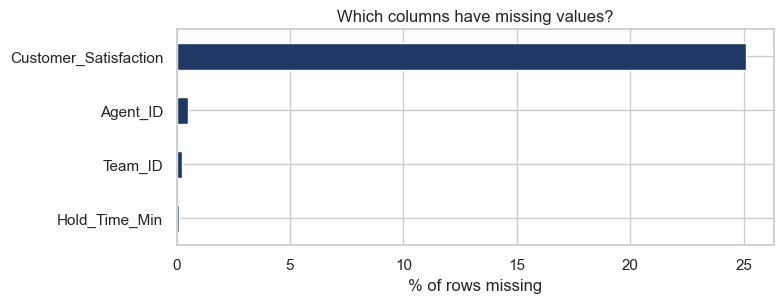

In [7]:
# Where is data missing?
miss = df_raw.isna().sum()
miss = (miss[miss > 0] / len(df_raw) * 100).sort_values()
ax = miss.plot(kind="barh", figsize=(8, 3.2), color="#1F3864")
ax.set_xlabel("% of rows missing")
ax.set_title("Which columns have missing values?")
plt.tight_layout(); plt.show()

In [8]:
# Cross-column consistency checks
cat_std = df_raw["Issue_Category"].str.strip().str.title()
hours = times.dt.hour

print("Subcategories under >1 category:",
      (df_raw.assign(cat=cat_std).groupby("Issue_Subcategory")["cat"].nunique() > 1).sum())   # 0

shift_hours = (pd.DataFrame({"Shift": df_raw["Shift"], "hour": hours}).dropna()
               .groupby("Shift")["hour"].agg(lambda s: sorted(s.unique().astype(int))))
print(shift_hours.to_string())   # Morning 6-13, Evening 14-21, Night 22-5

agent_teams = df_raw.dropna(subset=["Agent_ID", "Team_ID"]).groupby("Agent_ID")["Team_ID"].nunique()
print("Agents in >1 team:", int((agent_teams > 1).sum()))   # 0

Subcategories under >1 category: 0
Shift
Evening    [14, 15, 16, 17, 18, 19, 20, 21]
Morning        [6, 7, 8, 9, 10, 11, 12, 13]
Night            [0, 1, 2, 3, 4, 5, 22, 23]
Agents in >1 team: 0


Cell 5: Investigate before changing anything

Wait-time outliers:

count    60180.00
mean         3.72
std         13.35
min          0.00
50%          2.32
90%          6.99
95%          9.94
99%         17.92
99.9%       54.92
max        597.46
Values above 60 min: 60 | smallest: 180.02
Largest wait at or below 60: 57.13
Values between 60 and 180: 0
SLA_Met for >60 rows: {'Yes': 51, 'No': 9}


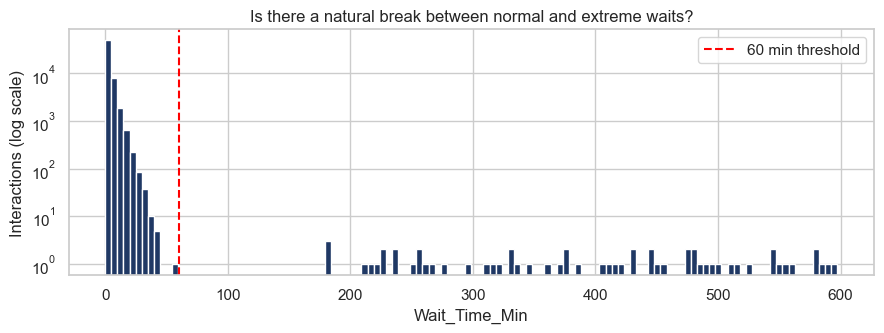

In [9]:
w = df_raw["Wait_Time_Min"]
print(w.describe(percentiles=[.5, .9, .95, .99, .999]).round(2).to_string())
print("Values above 60 min:", (w > 60).sum(), "| smallest:", w[w > 60].min())          # 60, 180.02
print("Largest wait at or below 60:", w[w <= 60].max())                                 # 57.13
print("Values between 60 and 180:", ((w > 60) & (w < 180)).sum())                       # 0
print("SLA_Met for >60 rows:", df_raw.loc[w > 60, "SLA_Met"].value_counts().to_dict())  # Yes 51, No 9

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(w, bins=120, color="#1F3864")
ax.set_yscale("log")
ax.axvline(60, color="red", linestyle="--", label="60 min threshold")
ax.set_xlabel("Wait_Time_Min"); ax.set_ylabel("Interactions (log scale)")
ax.set_title("Is there a natural break between normal and extreme waits?")
ax.legend(); plt.tight_layout(); plt.show()

Negative durations:

In [10]:
neg = df_raw.loc[df_raw["Interaction_Duration_Min"] < 0, "Interaction_Duration_Min"]
pos = df_raw.loc[df_raw["Interaction_Duration_Min"] > 0, "Interaction_Duration_Min"]
print("Negative values:", len(neg), "| range:", neg.min(), "to", neg.max())   # 120
print("Median of absolute negatives:", round(neg.abs().median(), 2))          # 7.05
print("Median of positive durations:", round(pos.median(), 2))                # 7.05

Negative values: 120 | range: -28.03 to -1.32
Median of absolute negatives: 7.05
Median of positive durations: 7.05


SLA target rule and hold time:

In [11]:
chan = df_raw["Channel"].str.strip().str.lower().replace({"e-mail": "email"})
is_email = chan.eq("email")
valid = df_raw["SLA_Target_Min"] > 0

rule_check = (df_raw[valid].assign(is_email=is_email[valid])
              .groupby(["Priority", "is_email"])["SLA_Target_Min"].agg(["nunique", "min", "max", "size"]))
print(rule_check.to_string())    # nunique = 1 everywhere: High 2/12, Medium 4/24, Low 8/48

digital = chan.isin(["chat", "email"])
print("Digital rows with Hold > 0:", int((df_raw.loc[digital, "Hold_Time_Min"] > 0).sum()))   # 0
print(df_raw.loc[df_raw["Hold_Time_Min"].isna(), "Channel"].str.strip().str.lower().value_counts().to_dict())

                   nunique  min  max   size
Priority is_email                          
High     False           1    2    2   8688
         True            1   12   12   1803
Low      False           1    8    8  16376
         True            1   48   48   3524
Medium   False           1    4    4  24343
         True            1   24   24   5346
Digital rows with Hold > 0: 0
{'inbound call': 38, 'email': 9, 'chat': 9, 'outbound call': 4}


Cell 6: Cleaning with a log. Run these in order, as separate cells if you like.

In [12]:
cleaning_log = []

def log_step(step, issue, rows, action, rationale):
    cleaning_log.append({"Step": step, "Issue": issue, "Rows affected": int(rows),
                         "Action": action, "Rationale": rationale})
    print(f"[{step}] {issue}: {int(rows)} rows -> {action}")

df = df_raw.copy()

In [13]:
# Step 1 - remove exact duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log_step(1, "Exact duplicate rows", before - len(df), "Removed (kept first copy)",
         "Identical copies; Interaction_ID must be unique")
assert df["Interaction_ID"].is_unique

[1] Exact duplicate rows: 180 rows -> Removed (kept first copy)


In [14]:
# Step 2 - standardize categorical text
channel_map = {"inbound call": "Inbound Call", "outbound call": "Outbound Call",
               "email": "Email", "e-mail": "Email", "chat": "Chat"}
new_channel = df["Channel"].str.strip().str.lower().map(channel_map)
assert new_channel.notna().all()
n_ch = (new_channel != df["Channel"]).sum()
df["Channel"] = new_channel

new_cat = df["Issue_Category"].str.strip().str.title()
n_cat = (new_cat != df["Issue_Category"]).sum()
df["Issue_Category"] = new_cat

log_step(2, "Inconsistent Channel names", n_ch, "Standardized", "Same values spelled differently")
log_step(2, "Inconsistent Issue_Category case", n_cat, "Standardized", "Lowercase variants split one category in group-bys")
assert set(df["Channel"]) == channel_ok and set(df["Issue_Category"]) == category_ok

[2] Inconsistent Channel names: 42 rows -> Standardized
[2] Inconsistent Issue_Category case: 250 rows -> Standardized


In [15]:
# Step 3 - invalid dates/times become NULL, rows retained
d = pd.to_datetime(df["Interaction_Date"], format="%Y-%m-%d", errors="coerce")
t = pd.to_datetime(df["Interaction_Time"], format="%H:%M:%S", errors="coerce")
log_step(3, "Invalid Interaction_Date", d.isna().sum(), "Set to NULL, row retained", "Impossible date; excluded only from time analysis")
log_step(3, "Invalid Interaction_Time", t.isna().sum(), "Set to NULL, row retained", "Impossible time; excluded only from hour/shift analysis")
df["Interaction_Date"] = d.dt.strftime("%Y-%m-%d")
df["Interaction_Time"] = t.dt.strftime("%H:%M:%S")

[3] Invalid Interaction_Date: 40 rows -> Set to NULL, row retained
[3] Invalid Interaction_Time: 40 rows -> Set to NULL, row retained


In [16]:
# Steps 4-5 - Team_ID recovery and missing Agent_ID
agent_team = df.dropna(subset=["Agent_ID", "Team_ID"]).groupby("Agent_ID")["Team_ID"].first()
fix = df["Team_ID"].isna() & df["Agent_ID"].notna()
df["DQ_Team_Recovered"] = fix.astype(int)
df.loc[fix, "Team_ID"] = df.loc[fix, "Agent_ID"].map(agent_team)
log_step(4, "Missing Team_ID", fix.sum(), "Recovered from Agent_ID, flagged", "Each agent belongs to exactly one team")

df["DQ_Agent_Missing"] = df["Agent_ID"].isna().astype(int)
log_step(5, "Missing Agent_ID", df["DQ_Agent_Missing"].sum(), "Retained as NULL, flagged",
         "Cannot be inferred; not filled with a fake agent so agent counts stay correct")
print("Team_ID still missing:", df["Team_ID"].isna().sum())   # 0

[4] Missing Team_ID: 150 rows -> Recovered from Agent_ID, flagged
[5] Missing Agent_ID: 300 rows -> Retained as NULL, flagged
Team_ID still missing: 0


In [17]:
# Steps 6-7 - negative durations and hold time
negmask = df["Interaction_Duration_Min"] < 0
df["DQ_Duration_Corrected"] = negmask.astype(int)
df.loc[negmask, "Interaction_Duration_Min"] = df.loc[negmask, "Interaction_Duration_Min"].abs()
log_step(6, "Negative Interaction_Duration_Min", negmask.sum(), "Absolute value, flagged",
         "Sign-entry error assumption (medians match); confirm with source system")

digital = df["Channel"].isin(["Chat", "Email"])
assert (df.loc[digital, "Hold_Time_Min"].dropna() == 0).all()
fill0 = df["Hold_Time_Min"].isna() & digital
df.loc[fill0, "Hold_Time_Min"] = 0
log_step(7, "Missing Hold_Time_Min on Chat/Email", fill0.sum(), "Set to 0", "No digital interaction has hold time > 0")
log_step(7, "Missing Hold_Time_Min on calls", df["Hold_Time_Min"].isna().sum(), "Retained as NULL", "Cannot assume 0 for voice calls")

[6] Negative Interaction_Duration_Min: 120 rows -> Absolute value, flagged
[7] Missing Hold_Time_Min on Chat/Email: 18 rows -> Set to 0
[7] Missing Hold_Time_Min on calls: 42 rows -> Retained as NULL


In [18]:
# Steps 8-9 - wait outliers and SLA target
df["DQ_Wait_Outlier"] = (df["Wait_Time_Min"] > 60).astype(int)
log_step(8, "Wait_Time_Min above 60 min", df["DQ_Wait_Outlier"].sum(), "Retained, flagged",
         "Nothing between 60 and 180 min, then 60 rows at 180-597; abnormal but not deleted without confirmation")

is_email = df["Channel"].eq("Email")
rule = (df[df["SLA_Target_Min"] > 0].assign(is_email=is_email)
        .groupby(["Priority", "is_email"])["SLA_Target_Min"].agg(["nunique", "first"]))
assert (rule["nunique"] == 1).all()
rule_map = rule["first"].to_dict()
zero = df["SLA_Target_Min"] == 0
df["DQ_SLA_Target_Corrected"] = zero.astype(int)
df.loc[zero, "SLA_Target_Min"] = [rule_map[(p, e)] for p, e in zip(df.loc[zero, "Priority"], is_email[zero])]
log_step(9, "SLA_Target_Min = 0", zero.sum(), "Restored from Priority/channel rule, flagged", "Rule has no exceptions in other rows")

[8] Wait_Time_Min above 60 min: 60 rows -> Retained, flagged
[9] SLA_Target_Min = 0: 100 rows -> Restored from Priority/channel rule, flagged


In [19]:
# Steps 10-12 - CSAT, SLA consistency, FCR logic
bad_csat = df["Customer_Satisfaction"].notna() & ~df["Customer_Satisfaction"].between(1, 5)
log_step(10, "Invalid Customer_Satisfaction", bad_csat.sum(), "Set to NULL", "Outside 1-5; imputing would invent survey results")
df.loc[bad_csat, "Customer_Satisfaction"] = np.nan

sla_calc = np.where(df["Wait_Time_Min"] <= df["SLA_Target_Min"], "Yes", "No")
df["DQ_SLA_Mismatch"] = (sla_calc != df["SLA_Met"]).astype(int)
log_step(11, "SLA_Met disagrees with Wait <= Target", df["DQ_SLA_Mismatch"].sum(), "Retained recorded value, flagged",
         "Cause unknown; report SLA as recorded and as recalculated")

fcr_bad = (df["First_Call_Resolution"] == "Yes") & (df["Resolution_Status"] != "Resolved")
df["DQ_FCR_Inconsistent"] = fcr_bad.astype(int)
log_step(12, "FCR = Yes but not Resolved", fcr_bad.sum(), "Retained, flagged", "FCR definition decided at KPI stage")

[10] Invalid Customer_Satisfaction: 80 rows -> Set to NULL
[11] SLA_Met disagrees with Wait <= Target: 141 rows -> Retained recorded value, flagged
[12] FCR = Yes but not Resolved: 711 rows -> Retained, flagged


Cell 7: Verify

In [20]:
checks = {
    "Row count is 60,000": len(df) == 60000,
    "Interaction_ID unique": df["Interaction_ID"].is_unique,
    "No negative durations": (df[num_cols] < 0).sum().sum() == 0,
    "CSAT within 1-5 or NULL": df["Customer_Satisfaction"].dropna().between(1, 5).all(),
    "SLA targets valid": set(df["SLA_Target_Min"]) == {2, 4, 8, 12, 24, 48},
    "No missing Team_ID": df["Team_ID"].notna().all(),
    "4 channels, 7 categories": df["Channel"].nunique() == 4 and df["Issue_Category"].nunique() == 7,
    "Dates in 2025": pd.to_datetime(df["Interaction_Date"]).dropna().dt.year.eq(2025).all(),
}
for k, v in checks.items():
    print("PASS" if v else "FAIL", "-", k)
assert all(checks.values())

PASS - Row count is 60,000
PASS - Interaction_ID unique
PASS - No negative durations
PASS - CSAT within 1-5 or NULL
PASS - SLA targets valid
PASS - No missing Team_ID
PASS - 4 channels, 7 categories
PASS - Dates in 2025


In [21]:
after = pd.DataFrame({"Missing (before)": df_raw.isna().sum(), "Missing (after)": df.isna().sum()})
after[(after != 0).any(axis=1)]

,Missing (before),Missing (after)
Agent_ID,301.0,300
Customer_Satisfaction,15090.0,15131
DQ_Agent_Missing,NaN,0
DQ_Duration_Corrected,NaN,0
DQ_FCR_Inconsistent,NaN,0
DQ_SLA_Mismatch,NaN,0
DQ_SLA_Target_Corrected,NaN,0
DQ_Team_Recovered,NaN,0
DQ_Wait_Outlier,NaN,0
Hold_Time_Min,60.0,42


In [22]:
df[num_cols + ["Customer_Satisfaction"]].describe(percentiles=[.5, .95, .99]).round(2)

,Interaction_Duration_Min,Wait_Time_Min,Hold_Time_Min,After_Call_Work_Min,Customer_Satisfaction
count,60000.00,60000.00,59958.00,60000.00,44869.00
mean,8.40,3.72,0.64,2.14,3.98
std,5.49,13.37,0.91,1.25,0.92
min,0.50,0.00,0.00,0.20,1.00
50%,7.05,2.32,0.31,1.89,4.00
95%,19.15,9.94,2.46,4.50,5.00
99%,27.42,17.94,4.05,6.06,5.00
max,62.48,597.46,10.92,12.02,5.00


Cell 8: Save

In [23]:
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_PATH, index=False)
pd.DataFrame(cleaning_log).to_csv(LOG_PATH, index=False)
print(df.shape)   # (60000, 35)

(60000, 35)


Cell 9: Load the cleaned data for ED

In [24]:
eda = pd.read_csv(CLEAN_PATH, parse_dates=["Interaction_Date"])
eda["Hour"] = pd.to_datetime(eda["Interaction_Time"], format="%H:%M:%S").dt.hour
eda["AHT_Min"] = eda["Interaction_Duration_Min"] + eda["Hold_Time_Min"] + eda["After_Call_Work_Min"]
eda["Wait_Clean"] = eda["Wait_Time_Min"].where(eda["DQ_Wait_Outlier"] == 0)   # excludes the 60 flagged outliers
eda["Escalated"]   = (eda["Escalation_Status"] == "Escalated").astype(int)
eda["Transferred"] = (eda["Transfer_Status"] == "Transferred").astype(int)
eda["Repeat"]      = (eda["Repeat_Interaction"] == "Yes").astype(int)
eda["Resolved"]    = (eda["Resolution_Status"] == "Resolved").astype(int)
eda["SLA_Flag"]    = (eda["SLA_Met"] == "Yes").astype(int)
eda["FCR_Recorded"] = (eda["First_Call_Resolution"] == "Yes").astype(int)
eda["FCR_Strict"]  = ((eda["First_Call_Resolution"] == "Yes") & (eda["Resolution_Status"] == "Resolved")).astype(int)
eda["Channel_Group"] = np.where(eda["Channel"] == "Email", "Email", "Calls & Chat")
print(eda.shape)   # (60000, 46)

IMG_DIR = ROOT / "images" / "eda"
IMG_DIR.mkdir(parents=True, exist_ok=True)

def finish(name):
    plt.tight_layout()
    plt.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def label_bars(ax, fmt="{:.1f}", horizontal=False):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if np.isnan(v):
            continue
        if horizontal:
            ax.text(v, p.get_y() + p.get_height() / 2, " " + fmt.format(v), va="center", fontsize=8)
        else:
            ax.text(p.get_x() + p.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=8)

(60000, 46)


Cell 10: KPI table

In [25]:
sla_recalc = (eda["Wait_Time_Min"] <= eda["SLA_Target_Min"]).mean() * 100
kpi = pd.DataFrame({
    "KPI": ["Total interactions", "AHT (min)", "FCR - recorded (%)", "FCR - strict (%)", "SLA - recorded (%)",
            "SLA - recalculated (%)", "Escalation rate (%)", "Transfer rate (%)", "Repeat rate (%)",
            "Average CSAT (valid responses)"],
    "Value": [len(eda), eda["AHT_Min"].mean(), eda["FCR_Recorded"].mean() * 100, eda["FCR_Strict"].mean() * 100,
              eda["SLA_Flag"].mean() * 100, sla_recalc, eda["Escalated"].mean() * 100,
              eda["Transferred"].mean() * 100, eda["Repeat"].mean() * 100, eda["Customer_Satisfaction"].mean()],
})
kpi["Value"] = kpi["Value"].round(2)
kpi

,KPI,Value
0,Total interactions,60000.00
1,AHT (min),11.18
2,FCR - recorded (%),74.00
3,FCR - strict (%),72.82
4,SLA - recorded (%),84.89
5,SLA - recalculated (%),84.92
6,Escalation rate (%),9.74
7,Transfer rate (%),8.30
8,Repeat rate (%),13.28
9,Average CSAT (valid responses),3.98


Cell 11: Which months are busiest?

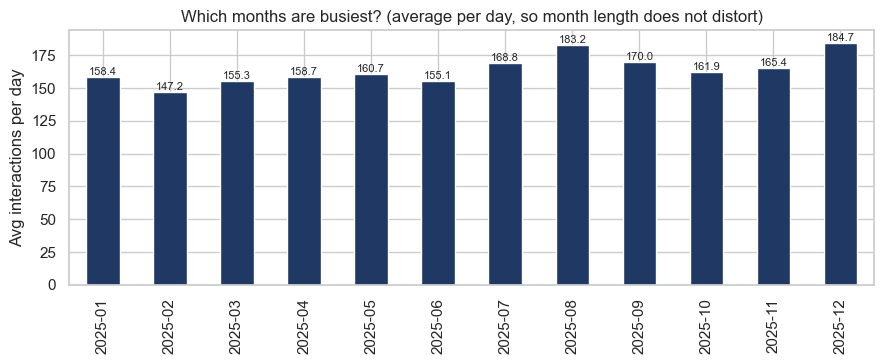

In [26]:
daily = eda.dropna(subset=["Interaction_Date"]).groupby("Interaction_Date").size()
monthly_avg = daily.groupby(daily.index.to_period("M")).mean()
monthly_avg.index = monthly_avg.index.astype(str)

fig, ax = plt.subplots(figsize=(9, 3.8))
monthly_avg.plot(kind="bar", ax=ax, color="#1F3864")
label_bars(ax)
ax.set_ylabel("Avg interactions per day"); ax.set_xlabel("")
ax.set_title("Which months are busiest? (average per day, so month length does not distort)")
finish("01_monthly_volume")

Cell 12: Which days and hours are busiest?

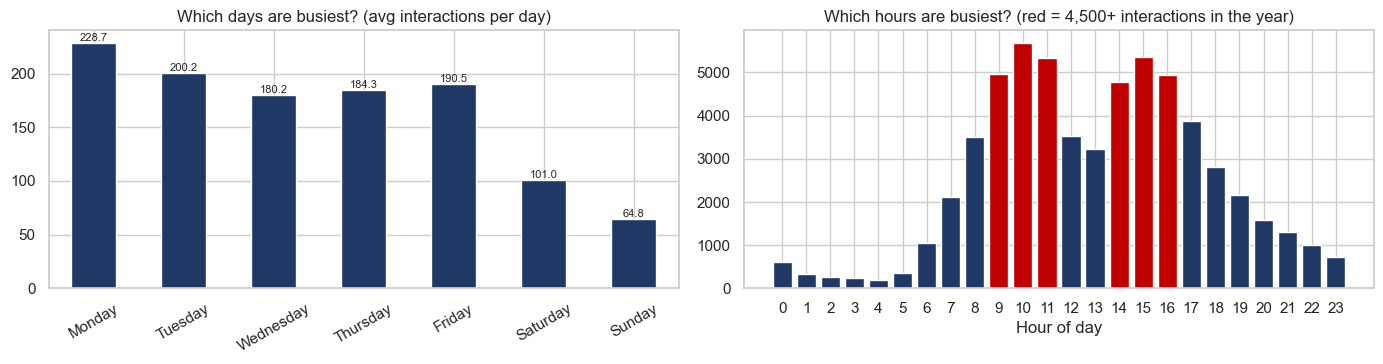

In [27]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = daily.groupby(daily.index.day_name()).mean().reindex(order)
hr = (eda.dropna(subset=["Hour"]).assign(Hour=lambda x: x["Hour"].astype(int))
      .groupby("Hour").size())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
wd.plot(kind="bar", ax=axes[0], color="#1F3864"); label_bars(axes[0])
axes[0].set_title("Which days are busiest? (avg interactions per day)")
axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(hr.index, hr.values, color=["#C00000" if v >= 4500 else "#1F3864" for v in hr.values])
axes[1].set_title("Which hours are busiest? (red = 4,500+ interactions in the year)")
axes[1].set_xlabel("Hour of day"); axes[1].set_xticks(range(0, 24))
finish("02_weekday_hour_volume")

Cell 13: Which channels and issues create the workload?

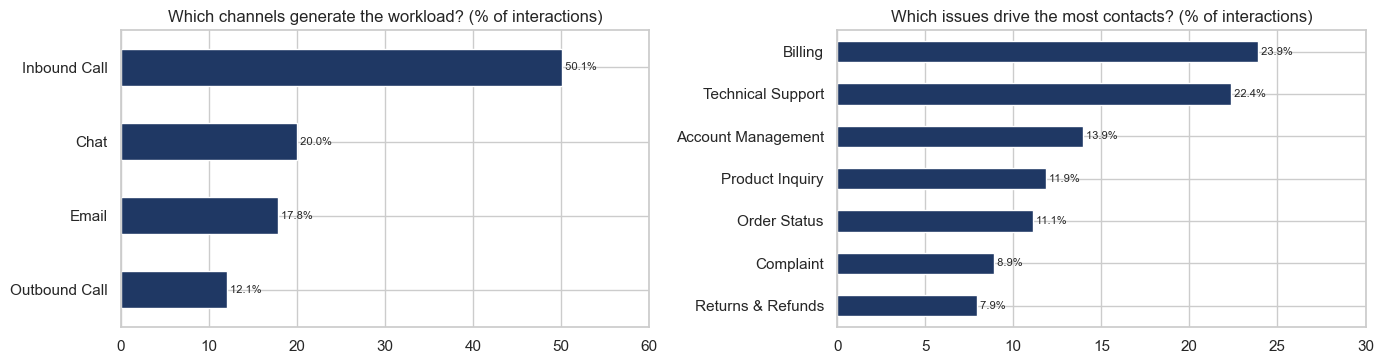

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
ch = (eda["Channel"].value_counts(normalize=True) * 100).sort_values()
ch.plot(kind="barh", ax=axes[0], color="#1F3864"); label_bars(axes[0], "{:.1f}%", True)
axes[0].set_title("Which channels generate the workload? (% of interactions)"); axes[0].set_xlim(0, 60)

iss = (eda["Issue_Category"].value_counts(normalize=True) * 100).sort_values()
iss.plot(kind="barh", ax=axes[1], color="#1F3864"); label_bars(axes[1], "{:.1f}%", True)
axes[1].set_title("Which issues drive the most contacts? (% of interactions)"); axes[1].set_xlim(0, 30)
for a in axes:
    a.set_ylabel("")
finish("03_channel_issue_mix")

Cell 14: Is workload shared evenly across agents and teams?

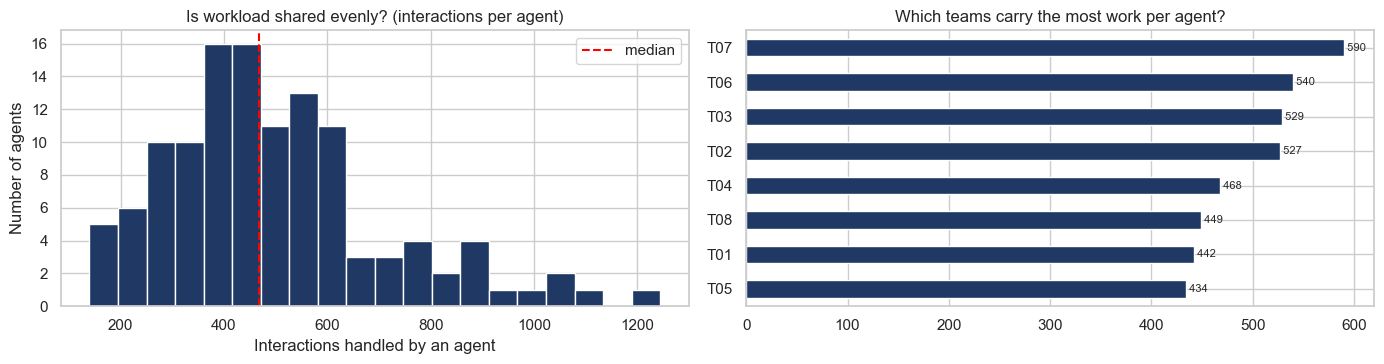

In [29]:
agent = (eda.dropna(subset=["Agent_ID"]).groupby("Agent_ID")
         .agg(Team_ID=("Team_ID", "first"), interactions=("Interaction_ID", "size"),
              fcr_strict=("FCR_Strict", "mean"), csat=("Customer_Satisfaction", "mean"),
              aht=("AHT_Min", "mean"), esc=("Escalated", "mean")).reset_index())
team_load = agent.groupby("Team_ID")["interactions"].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(agent["interactions"], bins=20, color="#1F3864", edgecolor="white")
axes[0].axvline(agent["interactions"].median(), color="red", linestyle="--", label="median")
axes[0].set_title("Is workload shared evenly? (interactions per agent)")
axes[0].set_xlabel("Interactions handled by an agent"); axes[0].set_ylabel("Number of agents"); axes[0].legend()

team_load.plot(kind="barh", ax=axes[1], color="#1F3864"); label_bars(axes[1], "{:.0f}", True)
axes[1].set_title("Which teams carry the most work per agent?"); axes[1].set_ylabel("")
finish("04_agent_team_workload")

Cell 15: Which agents are strong or weak on quality? (uses agent from Cell 14)

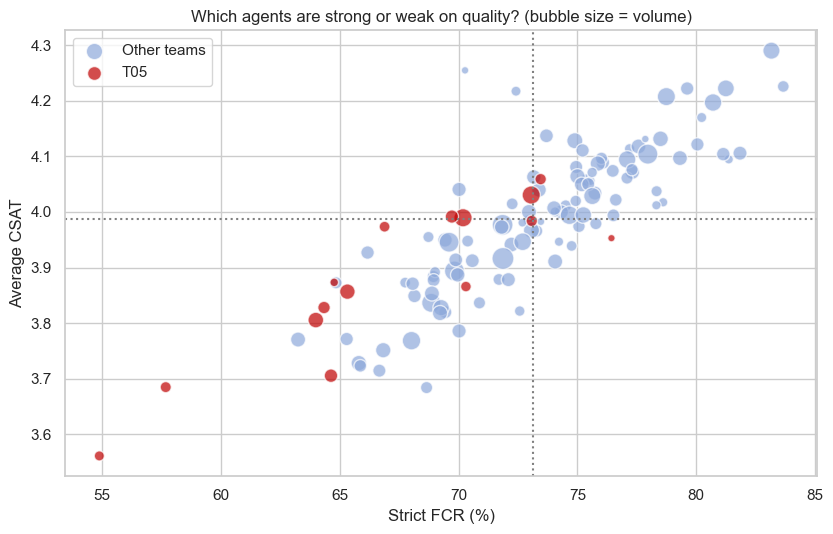

In [30]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for name, g, col in [("Other teams", agent[agent["Team_ID"] != "T05"], "#8EA9DB"),
                     ("T05", agent[agent["Team_ID"] == "T05"], "#C00000")]:
    ax.scatter(g["fcr_strict"] * 100, g["csat"], s=g["interactions"] / 5, alpha=0.7,
               color=col, label=name, edgecolor="white")
ax.axvline(agent["fcr_strict"].median() * 100, color="grey", linestyle=":")
ax.axhline(agent["csat"].median(), color="grey", linestyle=":")
ax.set_xlabel("Strict FCR (%)"); ax.set_ylabel("Average CSAT")
ax.set_title("Which agents are strong or weak on quality? (bubble size = volume)")
ax.legend()
finish("05_agent_quality")

Cell 16: Which issues take the longest to handle?

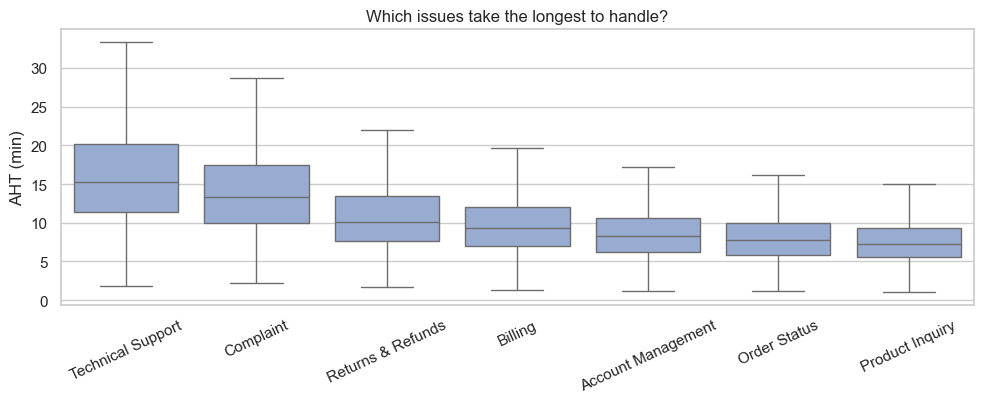

In [31]:
med_order = eda.groupby("Issue_Category")["AHT_Min"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=eda, x="Issue_Category", y="AHT_Min", order=med_order,
            showfliers=False, color="#8EA9DB", ax=ax)
ax.set_xlabel(""); ax.set_ylabel("AHT (min)"); ax.tick_params(axis="x", rotation=25)
ax.set_title("Which issues take the longest to handle?")
finish("06_aht_by_issue")

Cell 17: How long do customers wait compared with the SLA targets?

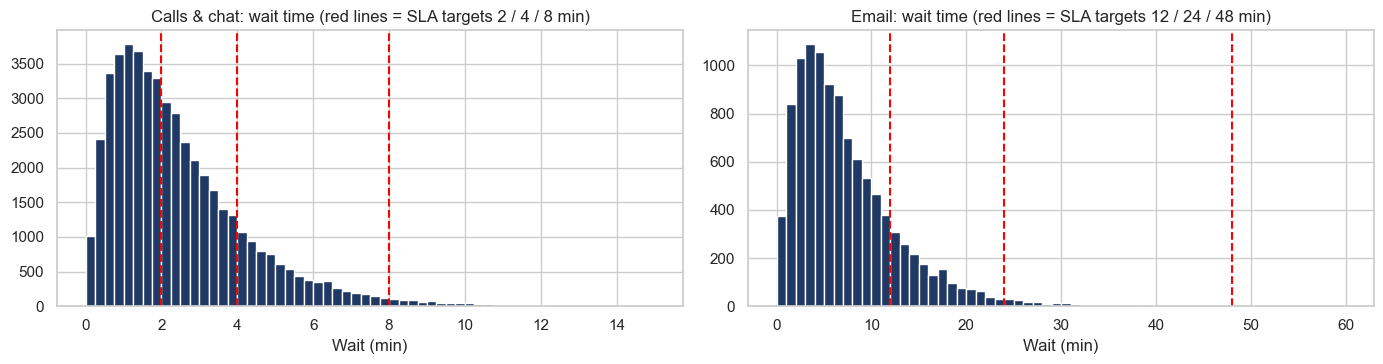

In [32]:
calls = eda.loc[eda["Channel_Group"] == "Calls & Chat", "Wait_Clean"].dropna()
mail  = eda.loc[eda["Channel_Group"] == "Email", "Wait_Clean"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(calls, bins=60, range=(0, 15), color="#1F3864")
for t in (2, 4, 8):
    axes[0].axvline(t, color="red", linestyle="--")
axes[0].set_title("Calls & chat: wait time (red lines = SLA targets 2 / 4 / 8 min)"); axes[0].set_xlabel("Wait (min)")

axes[1].hist(mail, bins=60, range=(0, 60), color="#1F3864")
for t in (12, 24, 48):
    axes[1].axvline(t, color="red", linestyle="--")
axes[1].set_title("Email: wait time (red lines = SLA targets 12 / 24 / 48 min)"); axes[1].set_xlabel("Wait (min)")
finish("07_wait_time_vs_targets")

Cell 18: When do SLA breaches happen?

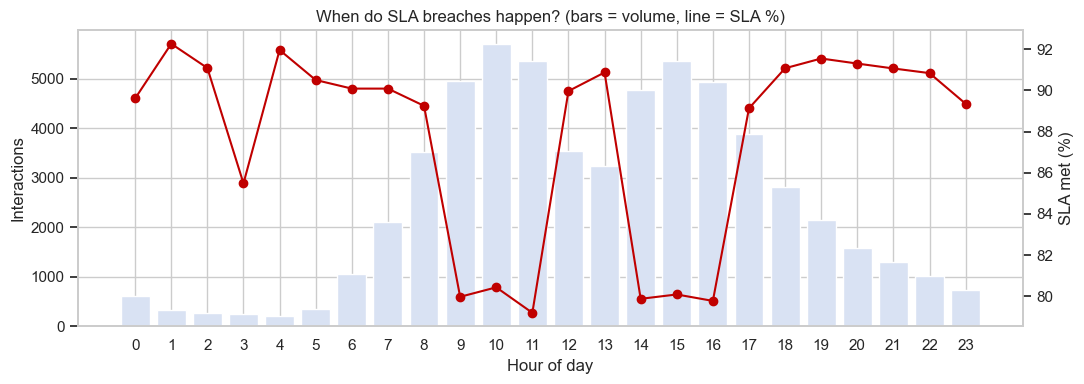

In [33]:
h = (eda.dropna(subset=["Hour"]).assign(Hour=lambda x: x["Hour"].astype(int))
     .groupby("Hour").agg(n=("SLA_Flag", "size"), sla=("SLA_Flag", "mean")))

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(h.index, h["n"], color="#D9E2F3"); ax1.set_ylabel("Interactions"); ax1.set_xlabel("Hour of day")
ax2 = ax1.twinx()
ax2.plot(h.index, h["sla"] * 100, color="#C00000", marker="o")
ax2.set_ylabel("SLA met (%)"); ax2.grid(False)
ax1.set_xticks(range(0, 24))
ax1.set_title("When do SLA breaches happen? (bars = volume, line = SLA %)")
finish("08_sla_by_hour")

Cell 19: Does priority change waiting or SLA?

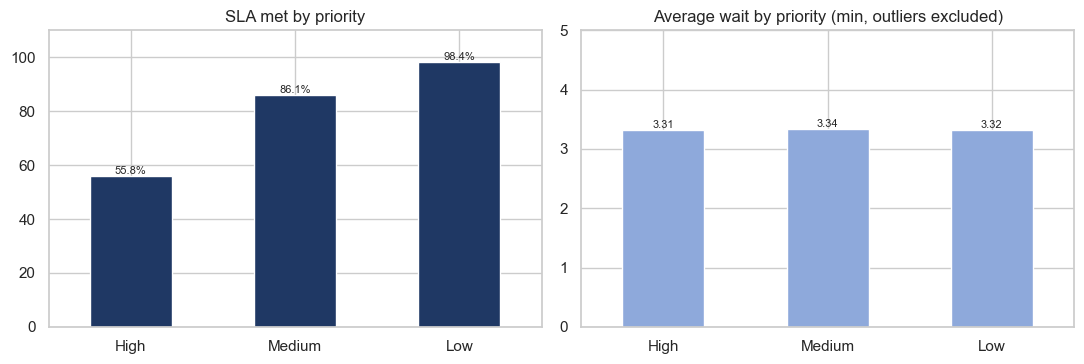

In [34]:
pr = ["High", "Medium", "Low"]
sla_p  = eda.groupby("Priority")["SLA_Flag"].mean().reindex(pr) * 100
wait_p = eda.groupby("Priority")["Wait_Clean"].mean().reindex(pr)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sla_p.plot(kind="bar", ax=axes[0], color="#1F3864"); label_bars(axes[0], "{:.1f}%")
axes[0].set_title("SLA met by priority"); axes[0].set_ylim(0, 110)
wait_p.plot(kind="bar", ax=axes[1], color="#8EA9DB"); label_bars(axes[1], "{:.2f}")
axes[1].set_title("Average wait by priority (min, outliers excluded)"); axes[1].set_ylim(0, 5)
for a in axes:
    a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
finish("09_priority_sla_wait")

Cell 20: Where do escalations come from?

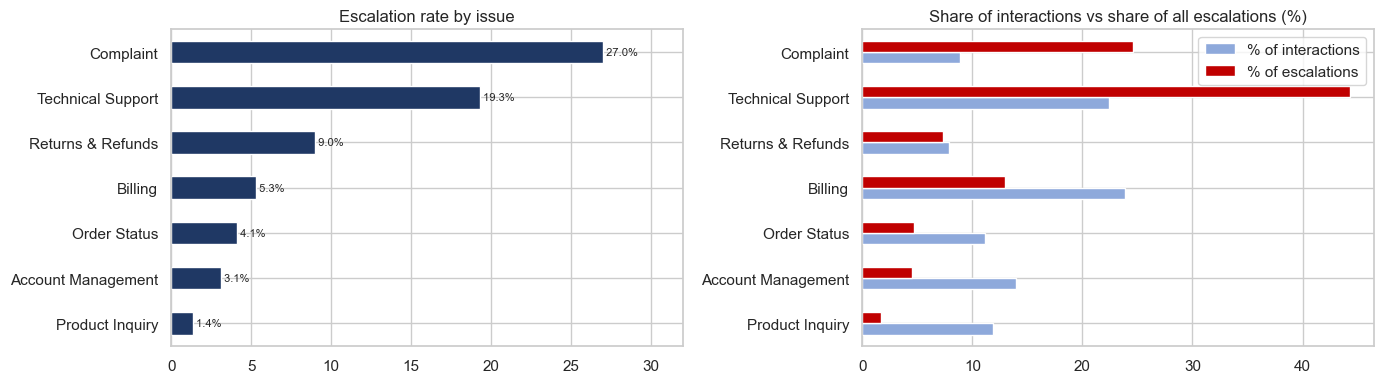

In [35]:
esc = eda.groupby("Issue_Category").agg(rate=("Escalated", "mean"), n=("Escalated", "size"), e=("Escalated", "sum"))
esc["rate"] *= 100
esc["share_interactions"] = esc["n"] / esc["n"].sum() * 100
esc["share_escalations"]  = esc["e"] / esc["e"].sum() * 100
esc = esc.sort_values("rate")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
esc["rate"].plot(kind="barh", ax=axes[0], color="#1F3864"); label_bars(axes[0], "{:.1f}%", True)
axes[0].set_title("Escalation rate by issue"); axes[0].set_xlim(0, 32)
esc[["share_interactions", "share_escalations"]].plot(kind="barh", ax=axes[1], color=["#8EA9DB", "#C00000"])
axes[1].set_title("Share of interactions vs share of all escalations (%)")
axes[1].legend(["% of interactions", "% of escalations"])
for a in axes:
    a.set_ylabel("")
finish("10_escalation_by_issue")

Cell 21: What goes with low customer satisfaction?

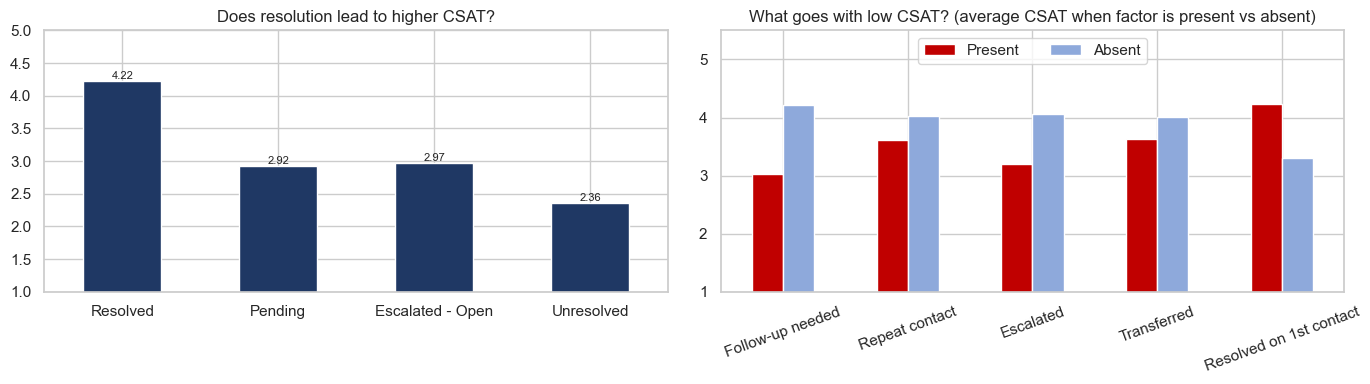

In [36]:
cs = eda.dropna(subset=["Customer_Satisfaction"])
res_order = ["Resolved", "Pending", "Escalated - Open", "Unresolved"]
by_res = cs.groupby("Resolution_Status")["Customer_Satisfaction"].mean().reindex(res_order)

pairs = [("Follow-up needed", cs["Follow_Up_Required"] == "Yes"), ("Repeat contact", cs["Repeat"] == 1),
         ("Escalated", cs["Escalated"] == 1), ("Transferred", cs["Transferred"] == 1),
         ("Resolved on 1st contact", cs["FCR_Strict"] == 1)]
fac = pd.DataFrame([{"factor": n, "Present": cs.loc[m, "Customer_Satisfaction"].mean(),
                     "Absent": cs.loc[~m, "Customer_Satisfaction"].mean()} for n, m in pairs]).set_index("factor")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_res.plot(kind="bar", ax=axes[0], color="#1F3864"); label_bars(axes[0], "{:.2f}")
axes[0].set_ylim(1, 5); axes[0].set_title("Does resolution lead to higher CSAT?")
axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)

fac.plot(kind="bar", ax=axes[1], color=["#C00000", "#8EA9DB"])
axes[1].set_ylim(1, 5.5); axes[1].legend(ncol=2, loc="upper center")
axes[1].set_title("What goes with low CSAT? (average CSAT when factor is present vs absent)")
axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=20)
finish("11_csat_drivers")

Cell 22: Which issues generate repeat contacts, and how are interactions resolved?

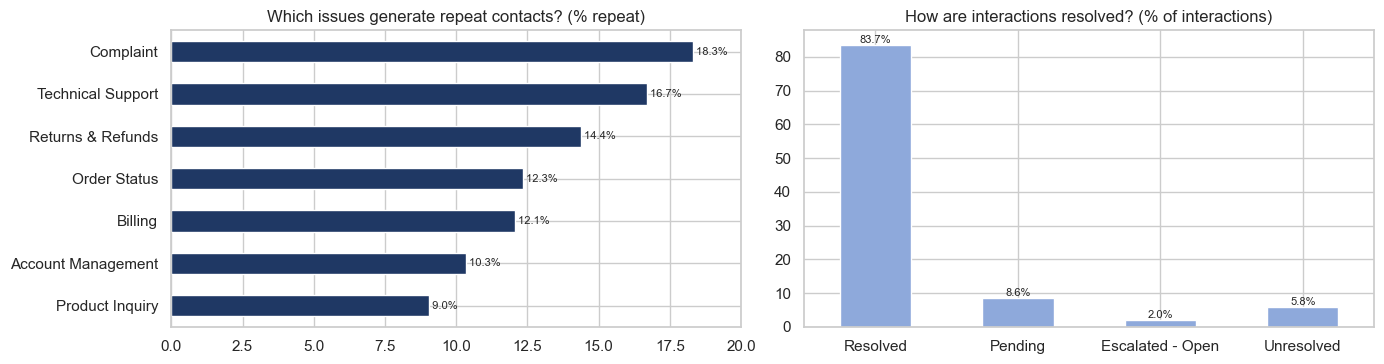

In [37]:
rep = (eda.groupby("Issue_Category")["Repeat"].mean() * 100).sort_values()
resol = (eda["Resolution_Status"].value_counts(normalize=True) * 100).reindex(res_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
rep.plot(kind="barh", ax=axes[0], color="#1F3864"); label_bars(axes[0], "{:.1f}%", True)
axes[0].set_title("Which issues generate repeat contacts? (% repeat)"); axes[0].set_xlim(0, 20); axes[0].set_ylabel("")
resol.plot(kind="bar", ax=axes[1], color="#8EA9DB"); label_bars(axes[1], "{:.1f}%")
axes[1].set_title("How are interactions resolved? (% of interactions)")
axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
finish("12_repeat_and_resolution")